# Notebook 03 — Logistic Regression

**Author:** K.G.L. Sandeepa (MS26929378)

The first of the two supervised algorithms the brief requires. Notebook 04 covers Random
Forest; notebook 05 puts them side by side on the sealed test set.

Logistic Regression is the **interpretable** half of the pair: it produces one coefficient
per feature, which reads directly as an odds ratio for the report and the viva. This
notebook covers three framings on the **same split and pipeline** defined in notebook 02:

1. **Three-class** — Dropout / Enrolled / Graduate, the headline result.
2. **Binary** — Dropout vs rest, which unlocks ROC/PR curves, a threshold sweep, and a
   SMOTE-vs-class-weight comparison that three classes do not allow cleanly.
3. **First-semester-only** — an honest *early-warning* model, deployable before year one ends.

**Background (from the labs).** Logistic Regression forms a linear score per class and maps
it to a probability — sigmoid for two classes, softmax for three (Lab 05). Its `C` is the
*inverse* of an L2 penalty (Lab 04, Ridge), so a smaller `C` shrinks the coefficients
harder. Features are standardised because the solver is gradient-based and L2 penalises
large-scale and small-scale features unequally otherwise (Lab 04). The evaluation protocol
and SMOTE come from Lab 08.

**Discipline.** Every number below is cross-validated on the 3,539-row development set. The
885-row test set is **not touched here** — it is evaluated once, for both algorithms, in
notebook 05. All encoding, scaling and PCA happen *inside* the pipeline, so they are
re-fitted on each training fold and never see the data they are scored against.

## 1 · Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import data
import preprocess
import evaluation as ev
import viz

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, precision_score, recall_score,
                             f1_score, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
viz.set_accessible_style()

FIGURES = ROOT / "reports" / "figures"
PROC = ROOT / "data" / "processed"
FIGURES.mkdir(parents=True, exist_ok=True)
PROC.mkdir(parents=True, exist_ok=True)

X_dev, X_test, y_dev, y_test = data.make_splits()
CV = data.cv_splitter()
CLASSES = ev.CLASS_ORDER  # ['Dropout', 'Enrolled', 'Graduate']
print("development rows:", len(X_dev))
print("test rows held back:", len(X_test))
print("random state:", data.RANDOM_STATE)

development rows: 3539
test rows held back: 885
random state: 42


## 2 · The data and the sealed split

The split comes from `data.make_splits()`, the single stratified 80/20 split shared by every
notebook. Stratification preserves the 49.9 / 32.1 / 17.9 class shares in both halves, which
matters because `Enrolled` is only 17.9% of the data.

In [2]:
shares = pd.DataFrame({
    "dev %": (y_dev.value_counts(normalize=True) * 100).round(2),
    "test %": (y_test.value_counts(normalize=True) * 100).round(2),
    "dev n": y_dev.value_counts(),
}).loc[CLASSES]
print(shares, "\n")
print("features:", X_dev.shape[1],
      f"({len(data.NOMINAL_CODED)} nominal + {len(data.BINARY)} binary + {len(data.CONTINUOUS_ALL)} continuous)")
assert len(X_test) == 885, "the test set must stay sealed until notebook 05"
print("test set sealed:", len(X_test), "rows untouched")

          dev %  test %  dev n
Target                        
Dropout   32.13   32.09   1137
Enrolled  17.94   17.97    635
Graduate  49.93   49.94   1767 

features: 39 (9 nominal + 7 binary + 23 continuous)
test set sealed: 885 rows untouched


## 3 · Baseline — the accuracy trap in one line

`DummyClassifier(strategy="most_frequent")` predicts *Graduate* every time. Reporting it
first makes every later number mean something: a model has to beat 49.9% accuracy *and* a
macro-F1 of about 0.22 before it has done anything at all.

In [3]:
dummy = DummyClassifier(strategy="most_frequent")
acc = cross_validate(dummy, X_dev, y_dev, cv=CV, scoring="accuracy")["test_score"].mean()
f1m = cross_validate(dummy, X_dev, y_dev, cv=CV, scoring="f1_macro")["test_score"].mean()
print(f"majority-class baseline (5-fold dev):  accuracy = {acc:.3f}   macro-F1 = {f1m:.3f}")
print("high accuracy, useless macro-F1 -> accuracy alone would hide a do-nothing model.")

majority-class baseline (5-fold dev):  accuracy = 0.499   macro-F1 = 0.222
high accuracy, useless macro-F1 -> accuracy alone would hide a do-nothing model.


## 4 · Three-class Logistic Regression (headline)

`GridSearchCV` over the regularisation strength `C` and `class_weight`, scored on **macro-F1**
(never accuracy), across 5 stratified folds of the development set only. Macro-F1 weights the
three classes equally, so an improvement on the hard `Enrolled` class counts as much as one on
`Graduate`.

In [4]:
logreg = preprocess.build_pipeline(
    LogisticRegression(max_iter=5000, random_state=data.RANDOM_STATE), variant="all"
)
grid = GridSearchCV(
    logreg,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0],
                "model__class_weight": [None, "balanced"]},
    scoring="f1_macro", cv=CV, n_jobs=-1, refit=True,
)
grid.fit(X_dev, y_dev)
BEST_C = grid.best_params_["model__C"]
BEST_W = grid.best_params_["model__class_weight"]
print("best params:", {k.replace("model__", ""): v for k, v in grid.best_params_.items()})
print(f"best dev macro-F1: {grid.best_score_:.4f}\n")

log = (pd.DataFrame(grid.cv_results_)[["param_model__C", "param_model__class_weight",
                                       "mean_test_score", "std_test_score"]]
       .sort_values("mean_test_score", ascending=False)
       .rename(columns={"param_model__C": "C", "param_model__class_weight": "class_weight",
                        "mean_test_score": "mean_f1_macro", "std_test_score": "std"}))
print("GridSearch trial log (the report asks for this):")
print(log.to_string(index=False))

best params: {'C': 0.1, 'class_weight': 'balanced'}
best dev macro-F1: 0.7134

GridSearch trial log (the report asks for this):
    C class_weight  mean_f1_macro      std
 0.10     balanced       0.713433 0.014690
10.00     balanced       0.710977 0.014548
 1.00     balanced       0.709789 0.012486
10.00          NaN       0.701677 0.014039
 0.01     balanced       0.701535 0.015498
 1.00          NaN       0.698989 0.018101
 0.10          NaN       0.695553 0.021751
 0.01          NaN       0.661170 0.022708


In [5]:
# Cross-validated metrics for the tuned model, and the out-of-fold confusion matrix.
best3 = grid.best_estimator_
scoring = ["accuracy", "balanced_accuracy", "f1_macro", "precision_macro", "recall_macro"]
cvres = cross_validate(best3, X_dev, y_dev, cv=CV, scoring=scoring)
print("tuned LR, 5-fold dev metrics:")
for m in scoring:
    print(f"  {m:20s}: {cvres['test_'+m].mean():.3f} +/- {cvres['test_'+m].std():.3f}")

oof = cross_val_predict(best3, X_dev, y_dev, cv=CV)
cm = ev.confusion_frame(y_dev, oof)
print("\nout-of-fold confusion matrix (rows = true, cols = predicted):")
print(cm)
print("\nrow-normalised (recall per class, %):")
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))

tuned LR, 5-fold dev metrics:
  accuracy            : 0.755 +/- 0.014
  balanced_accuracy   : 0.721 +/- 0.016
  f1_macro            : 0.713 +/- 0.015
  precision_macro     : 0.716 +/- 0.015
  recall_macro        : 0.721 +/- 0.016



out-of-fold confusion matrix (rows = true, cols = predicted):
predicted  Dropout  Enrolled  Graduate
true                                  
Dropout        834       210        93
Enrolled        98       386       151
Graduate        76       240      1451

row-normalised (recall per class, %):
predicted  Dropout  Enrolled  Graduate
true                                  
Dropout       73.4      18.5       8.2
Enrolled      15.4      60.8      23.8
Graduate       4.3      13.6      82.1


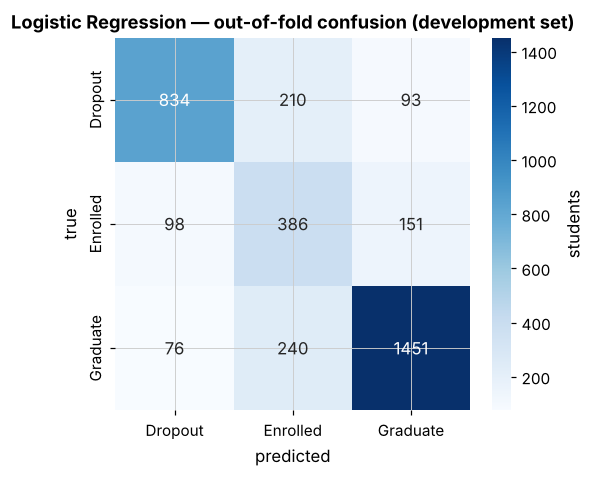

In [6]:
# Figure: out-of-fold confusion matrix. Colour reinforces the count, never replaces it.
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap=viz.SEQUENTIAL,
            cbar_kws={"label": "students"}, ax=ax,
            annot_kws={"fontsize": 11})
ax.set_title("Logistic Regression — out-of-fold confusion (development set)")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.savefig(FIGURES / "03_lr_confusion_dev.png")
plt.show()

## 5 · Interpreting the coefficients as odds

This is where Logistic Regression earns its place. For the **Dropout** class we take the
largest-magnitude coefficients and exponentiate them: `exp(coef)` is the multiplicative change
in the *odds* of dropping out for a one-standard-deviation change in that (standardised)
feature, with everything else held constant. A student-support office needs a reason it can
act on, not just a flag — this is that reason.

top drivers of the DROPOUT class (standardised features):
                                        coefficient  odds_ratio
Tuition fees up to date                      -1.385       0.250
Course_9853                                   0.585       1.796
Course_171                                   -0.580       0.560
Father's occupation_infrequent_sklearn       -0.571       0.565
Curricular units 2nd sem (approved)          -0.570       0.566
approval_rate_2nd                            -0.544       0.581
Curricular units 2nd sem (enrolled)           0.541       1.717
Course_9130                                   0.532       1.703
total_approved                               -0.487       0.615
Mother's occupation_0                         0.474       1.607
Mother's qualification_34                     0.411       1.508
Curricular units 1st sem (approved)          -0.383       0.682


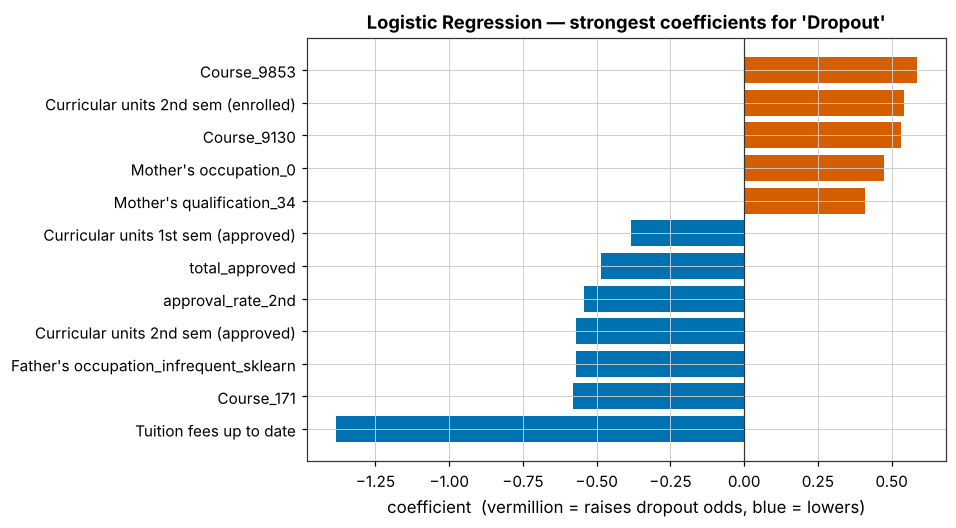

In [7]:
best3.fit(X_dev, y_dev)
names = best3.named_steps["prep"].get_feature_names_out()
clf = best3.named_steps["model"]
di = list(clf.classes_).index("Dropout")
coef = pd.Series(clf.coef_[di], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)

table = pd.DataFrame({"coefficient": top.round(3), "odds_ratio": np.exp(top).round(3)})
print("top drivers of the DROPOUT class (standardised features):")
print(table.to_string())

ordered = top.sort_values()
colors = [viz.POS if v > 0 else viz.NEG for v in ordered]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(ordered.index, ordered.values, color=colors)
ax.axvline(0, color="#333333", lw=0.8)
ax.set_title("Logistic Regression — strongest coefficients for 'Dropout'")
ax.set_xlabel("coefficient  (vermillion = raises dropout odds, blue = lowers)")
fig.savefig(FIGURES / "03_lr_coefficients.png")
plt.show()

## 6 · Dimensionality reduction — all vs selection vs PCA  *(rubric criterion 3)*

The preprocessing flow is **standardise → encode → reduce**, and the brief asks for reduction
*both* ways. The three representations are compared under the **same** Logistic Regression
(tuned `C`, balanced weights) and the **same** cross-validation:

- **All features** — the standardised + one-hot matrix (the headline model).
- **Feature *selection*** — keep original columns, drop the weakest with `SelectKBest` (ANOVA F).
  Stays interpretable.
- **PCA (feature *extraction*)** — the **standardised** continuous block is replaced by the
  principal components that keep 95% of its variance; the one-hot dummies and 0/1 flags are
  **not** rotated. PCA is fitted *inside* the pipeline, on training folds only, so there is no
  leakage. Standardisation before PCA is essential — on unscaled columns the component with the
  largest raw variance would dominate, the same lesson Lab 04 taught about gradient descent.

In [8]:
def lr(): return LogisticRegression(C=BEST_C, class_weight="balanced",
                                     max_iter=5000, random_state=data.RANDOM_STATE)

reps = {"all features": "all", "selection (ANOVA, k=40)": "reduced", "PCA (95% var)": "pca"}
rows = []
for label, variant in reps.items():
    pipe = preprocess.build_pipeline(lr(), variant=variant)
    r = cross_validate(pipe, X_dev, y_dev, cv=CV, scoring=["f1_macro", "accuracy"])
    rows.append({"representation": label,
                 "macro_F1": r["test_f1_macro"].mean(),
                 "accuracy": r["test_accuracy"].mean()})
rep_tbl = pd.DataFrame(rows).round(4)
print(rep_tbl.to_string(index=False))

pca_pipe = preprocess.build_pipeline(lr(), variant="pca").fit(X_dev, y_dev)
pca_step = pca_pipe.named_steps["prep"].named_transformers_["continuous"].named_steps["pca"]
print(f"\nPCA kept {pca_step.n_components_} components "
      f"from {len(data.CONTINUOUS_ALL)} standardised continuous features (95% variance).")

         representation  macro_F1  accuracy
           all features    0.7134    0.7547
selection (ANOVA, k=40)    0.7165    0.7553
          PCA (95% var)    0.7097    0.7479



PCA kept 13 components from 23 standardised continuous features (95% variance).


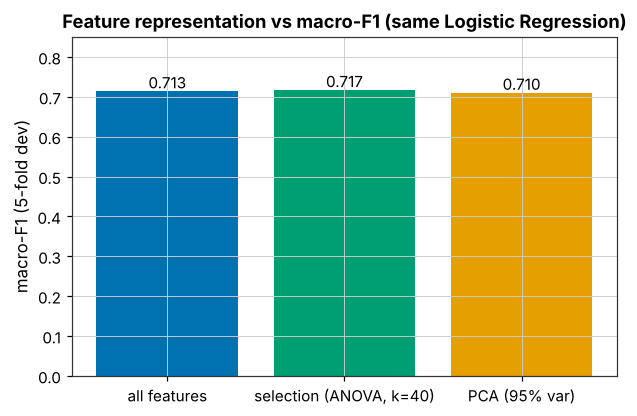

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 4))
bars = ax.bar(rep_tbl["representation"], rep_tbl["macro_F1"],
              color=[viz.OKABE_ITO["blue"], viz.OKABE_ITO["green"], viz.OKABE_ITO["orange"]])
for rect, v in zip(bars, rep_tbl["macro_F1"]):
    ax.text(rect.get_x() + rect.get_width()/2, v + 0.008, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylim(0, 0.85); ax.set_ylabel("macro-F1 (5-fold dev)")
ax.set_title("Feature representation vs macro-F1 (same Logistic Regression)")
fig.savefig(FIGURES / "03_feature_representation.png")
plt.show()

**Reading the result.** The three representations score within a hair of one another, so the
signal is not hidden in high dimensionality — selection and PCA buy almost nothing here. Given
that, the headline model keeps **all features**, because it is the only one of the three that
still yields coefficients and odds ratios. PCA earns its place in the report as the required
*dimensionality-reduction* step and as an honest demonstration of the
interpretability-versus-compression trade-off: it compresses 23 continuous columns to 13
components but forfeits the coefficient story section 5 is built on. A clearly argued negative
result is exactly what the rubric rewards.

## 7 · Binary framing — Dropout vs rest

Collapsing to two classes unlocks ROC-AUC, PR-AUC, a threshold sweep and a SMOTE-vs-class-weight
comparison — none of which work cleanly on three classes. The positive (Dropout) class is the
minority at 32.1%, so model selection is scored on **average precision** (PR-AUC). As in the
rest of the notebook, the test set stays sealed: every curve below is built from **out-of-fold**
predictions on the development set.

In [10]:
yb_dev = (y_dev == "Dropout").astype(int)

cw = preprocess.build_pipeline(
    LogisticRegression(max_iter=5000, class_weight="balanced", random_state=data.RANDOM_STATE),
    variant="all")

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
smote = ImbPipeline([("prep", preprocess.build_preprocessor()),
                     ("smote", SMOTE(random_state=data.RANDOM_STATE)),
                     ("model", LogisticRegression(max_iter=5000, random_state=data.RANDOM_STATE))])

for name, pipe in [("class_weight=balanced", cw), ("SMOTE", smote)]:
    ap = cross_validate(pipe, X_dev, yb_dev, cv=CV, scoring="average_precision")["test_score"]
    roc = cross_validate(pipe, X_dev, yb_dev, cv=CV, scoring="roc_auc")["test_score"]
    print(f"{name:22s}  PR-AUC = {ap.mean():.3f}   ROC-AUC = {roc.mean():.3f}")

class_weight=balanced   PR-AUC = 0.884   ROC-AUC = 0.923


SMOTE                   PR-AUC = 0.882   ROC-AUC = 0.922


out-of-fold  ROC-AUC = 0.923   PR-AUC = 0.883


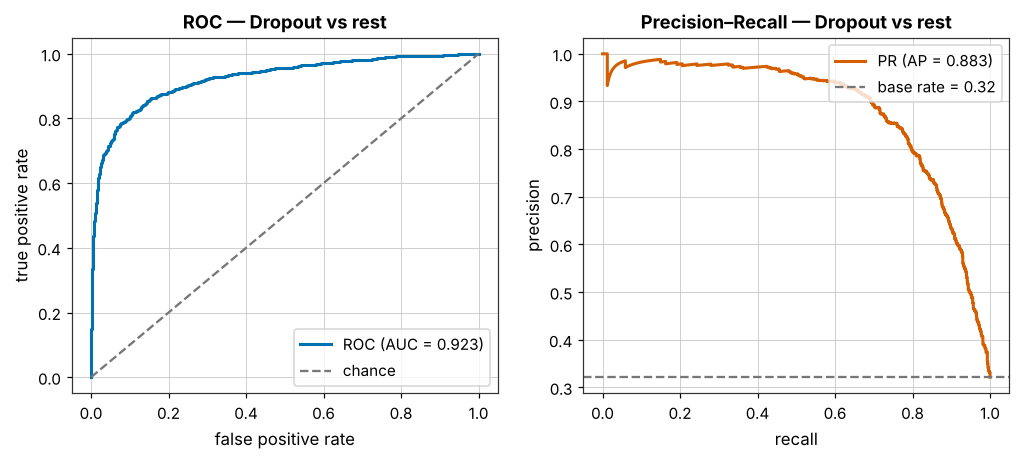

In [11]:
# Out-of-fold probabilities for the class-weight model -> ROC and PR curves on dev.
proba = cross_val_predict(cw, X_dev, yb_dev, cv=CV, method="predict_proba")[:, 1]
roc_auc = roc_auc_score(yb_dev, proba)
pr_auc = average_precision_score(yb_dev, proba)
print(f"out-of-fold  ROC-AUC = {roc_auc:.3f}   PR-AUC = {pr_auc:.3f}")

fpr, tpr, _ = roc_curve(yb_dev, proba)
prec, rec, _ = precision_recall_curve(yb_dev, proba)
base_rate = yb_dev.mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(fpr, tpr, color=viz.OKABE_ITO["blue"], lw=2, label=f"ROC (AUC = {roc_auc:.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="#777777", label="chance")
ax[0].set_title("ROC — Dropout vs rest"); ax[0].set_xlabel("false positive rate")
ax[0].set_ylabel("true positive rate"); ax[0].legend(loc="lower right")
ax[1].plot(rec, prec, color=viz.OKABE_ITO["vermillion"], lw=2, label=f"PR (AP = {pr_auc:.3f})")
ax[1].axhline(base_rate, ls="--", color="#777777", label=f"base rate = {base_rate:.2f}")
ax[1].set_title("Precision–Recall — Dropout vs rest"); ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision"); ax[1].legend(loc="upper right")
fig.savefig(FIGURES / "03_lr_roc_pr.png")
plt.show()

### 7b · Threshold sweep

A support office acts on **recall** — do not miss a student who will leave — but can only follow
up so many people, which is a **precision** constraint. Rather than pick the best-F1 point
blindly, we plot precision, recall and F1 against the decision threshold so the choice can be
defended by the office's real capacity.

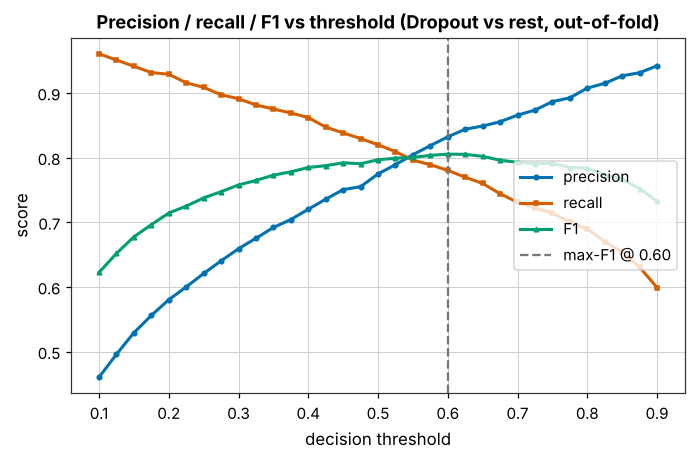

max-F1 threshold 0.60 is illustrative — the office should pick the point whose recall it has the capacity to follow up, not the best F1.


In [12]:
ths = np.linspace(0.1, 0.9, 33)
P = [precision_score(yb_dev, (proba >= t).astype(int), zero_division=0) for t in ths]
R = [recall_score(yb_dev, (proba >= t).astype(int)) for t in ths]
F = [f1_score(yb_dev, (proba >= t).astype(int), zero_division=0) for t in ths]
best_t = ths[int(np.argmax(F))]

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(ths, P, color=viz.OKABE_ITO["blue"], lw=2, marker="o", ms=3, label="precision")
ax.plot(ths, R, color=viz.OKABE_ITO["vermillion"], lw=2, marker="s", ms=3, label="recall")
ax.plot(ths, F, color=viz.OKABE_ITO["green"], lw=2, marker="^", ms=3, label="F1")
ax.axvline(best_t, ls="--", color="#777777", label=f"max-F1 @ {best_t:.2f}")
ax.set_xlabel("decision threshold"); ax.set_ylabel("score")
ax.set_title("Precision / recall / F1 vs threshold (Dropout vs rest, out-of-fold)")
ax.legend(loc="center right")
fig.savefig(FIGURES / "03_lr_threshold.png")
plt.show()
print(f"max-F1 threshold {best_t:.2f} is illustrative — the office should pick the point whose "
      f"recall it has the capacity to follow up, not the best F1.")

## 8 · Early-warning model — first semester only

The second-semester columns are only known once a student is most of a year into the course,
too late to intervene. The `first_sem` variant withholds them (and the second-semester
engineered features) and refits the three-class model. The gap against the full model is the
part of its performance that was **hindsight** — an availability question, not leakage, because
no second-semester column contains the label.

In [13]:
full = preprocess.build_pipeline(lr(), variant="all")
early = preprocess.build_pipeline(lr(), variant="first_sem")
f1_full = cross_validate(full, X_dev, y_dev, cv=CV, scoring="f1_macro")["test_score"].mean()
f1_early = cross_validate(early, X_dev, y_dev, cv=CV, scoring="f1_macro")["test_score"].mean()
print(f"full model (all features)   macro-F1 : {f1_full:.3f}")
print(f"early-warning (1st sem only) macro-F1 : {f1_early:.3f}")
print(f"hindsight gap (signal that arrives too late to act on) : {f1_full - f1_early:.3f}")

full model (all features)   macro-F1 : 0.713
early-warning (1st sem only) macro-F1 : 0.686
hindsight gap (signal that arrives too late to act on) : 0.027


## 9 · Save the development results for the comparison notebook

Notebook 05 combines this table with the Random Forest one and runs the single sealed-test
evaluation. The schema matches `evaluation.RESULTS_COLUMNS`, so the two tables concatenate
directly. Hyperparameters are held fixed across the four variants (tuned `C`, balanced weights),
so the only thing changing between rows is the feature set.

In [14]:
def lr_tuned(): return LogisticRegression(C=BEST_C, class_weight="balanced",
                                           max_iter=5000, random_state=data.RANDOM_STATE)

rows = [ev.majority_baseline(y_dev, y_dev)]
for variant, label in {"all": "all features", "reduced": "reduced",
                        "pca": "pca", "first_sem": "1st sem only"}.items():
    pipe = preprocess.build_pipeline(lr_tuned(), variant=variant)
    rows.append(ev.evaluate_cv(pipe, X_dev, y_dev, name="Logistic Regression",
                               variant=label, balancing="class_weight", cv=CV))
lr_results = ev.results_table(rows)
view = lr_results[["model", "variant", "accuracy", "balanced_accuracy",
                   "f1_macro", "mcc", "roc_auc", "recall_dropout", "recall_enrolled"]].round(4)
print(view.to_string(index=False))

lr_results.to_csv(PROC / "lr_cv_results.csv", index=False)
best_params = {"C": BEST_C, "class_weight": "balanced", "pca_components": int(pca_step.n_components_)}
json.dump(best_params, open(PROC / "lr_best_params.json", "w"), indent=2)
print("\nwritten: data/processed/lr_cv_results.csv and lr_best_params.json")
assert len(X_test) == 885, "test set must remain sealed"
print("test set still sealed:", len(X_test), "rows")

              model      variant  accuracy  balanced_accuracy  f1_macro    mcc  roc_auc  recall_dropout  recall_enrolled
  Majority baseline         none    0.4993             0.3333    0.2220 0.0000      NaN          0.0000           0.0000
Logistic Regression all features    0.7547             0.7208    0.7136 0.6113   0.8885          0.7335           0.6079
Logistic Regression      reduced    0.7553             0.7252    0.7165 0.6138   0.8887          0.7247           0.6315
Logistic Regression          pca    0.7480             0.7190    0.7097 0.6030   0.8831          0.7274           0.6236
Logistic Regression 1st sem only    0.7268             0.6932    0.6860 0.5682   0.8620          0.7115           0.5780

written: data/processed/lr_cv_results.csv and lr_best_params.json
test set still sealed: 885 rows


## 10 · Summary for the report

- Tuned Logistic Regression beats the majority baseline decisively on macro-F1, while accuracy
  alone would have hidden that — the accuracy trap the dataset's own authors flagged.
- **Enrolled** is the weakest class (smallest at 17.9% and genuinely ambiguous — a student
  behind schedule), visible as the off-diagonal mass in the confusion matrix.
- The coefficients give a plain-words story: being behind on tuition fees and low approval
  rates raise the odds of dropout; strong second-semester results lower them. Multicollinearity
  between the semester blocks inflates individual coefficients, which Random Forest (notebook 04)
  is largely immune to — a natural comparison point for notebook 05.
- **Dimensionality reduction:** all ≈ selection ≈ PCA on score, so the headline keeps all
  features and PCA is reported as the required reduction step that trades interpretability for
  compression.
- The early-warning gap quantifies how much of the full model's performance was hindsight.
- **Improvements / future work:** probability calibration, a cost-sensitive threshold tied to
  support-office capacity, treating the outcome as ordinal, and a fairness check across gender,
  scholarship and international status.